<a href="https://colab.research.google.com/github/LetheeshBalaji/DEEP-LEARNING/blob/main/RNN_LSTM_GRU_Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparative Analysis of RNN, LSTM and GRU for Sentiment Analysis
**Course:** 24ADI306 Deep Learning | **Assignment 3** | **CO3** (Apply & Analyze)

**Goal:** Classify IMDB movie reviews as positive or negative using three recurrent architectures and compare them on Accuracy, Precision, Recall, F1-score and Training Time.

**Experimental design (the concept before the code):**
- Only the recurrent layer changes between models (`SimpleRNN` vs `LSTM` vs `GRU`).
- Embedding size, units, dropout, optimizer, batch size, epochs, seed and data splits are identical, so any difference comes from the cell type.
- Test data is never used for training or model selection.

## 1. Setup
- `datasets` provides the IMDB reviews (25,000 train / 25,000 test, balanced).
- A fixed seed makes the three runs comparable.

In [1]:
!pip install -q datasets

In [2]:
import re, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, models

SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Hyperparameters (shared by all models)
MAX_WORDS = 20000   # vocabulary size
MAX_LEN   = 200     # tokens kept per review
EMB_DIM   = 128
UNITS     = 64
DROPOUT   = 0.3
BATCH     = 64
EPOCHS    = 5

## 2. Dataset
- **IMDB Large Movie Review Dataset**: binary labels (0 = negative, 1 = positive).
- Official test set (25k) is kept untouched; 20% of the training set (5k) becomes the **validation** set for monitoring.

In [4]:
ds = load_dataset("stanfordnlp/imdb")
train_text, train_label = ds["train"]["text"], np.array(ds["train"]["label"])
test_text,  test_label  = ds["test"]["text"],  np.array(ds["test"]["label"])

tr_x, va_x, tr_y, va_y = train_test_split(
    train_text, train_label, test_size=0.2, stratify=train_label, random_state=SEED)

print(len(tr_x), len(va_x), len(test_text))
print("Positive share (train):", tr_y.mean().round(3))
print(tr_x[0][:300])

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

20000 5000 25000
Positive share (train): 0.5
I have always been a huge James Bond fanatic! I have seen almost all of the films except for Die Another Day, and The World Is Not Enough. The graphic's for Everything Or Nothing are breathtaking! The voice talents......... WOW! I LOVE PIERCE BROSNAN! He is finally Bond in a video game! HE IS BOND! 


## 3. Preprocessing
Raw text must become fixed-length integer sequences. Three steps:
1. **Cleaning:** lowercase, strip HTML (`<br />`), keep letters only, collapse spaces. This shrinks the vocabulary by removing noise variants (`Great!`, `great`, `GREAT`).
2. **Tokenization:** map each word to an integer id. Only the `MAX_WORDS` most frequent words are kept; the rest become an `<OOV>` token. The tokenizer is **fit on training data only** to avoid leakage.
3. **Padding/truncation:** batches need equal length, so every review is cut or padded to `MAX_LEN`. Padding is added at the **front** (`pre`) so real words sit next to the final hidden state, which is what the classifier reads. Post-padding hurts a plain RNN because it must carry information across many padding steps.

In [5]:
def clean(t):
    t = t.lower()
    t = re.sub(r"<[^>]+>", " ", t)        # HTML tags
    t = re.sub(r"[^a-z\s]", " ", t)       # keep letters only
    return re.sub(r"\s+", " ", t).strip()

tr_c = [clean(t) for t in tr_x]
va_c = [clean(t) for t in va_x]
te_c = [clean(t) for t in test_text]

tok = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tok.fit_on_texts(tr_c)

def encode(texts):
    return pad_sequences(tok.texts_to_sequences(texts),
                         maxlen=MAX_LEN, padding="pre", truncating="post")

X_tr, X_va, X_te = encode(tr_c), encode(va_c), encode(te_c)
y_tr, y_va, y_te = tr_y, va_y, test_label

print(X_tr.shape, X_va.shape, X_te.shape)
print("Before:", tr_x[0][:80])
print("After :", tr_c[0][:80])
print("Ids   :", X_tr[0][-12:])

(20000, 200) (5000, 200) (25000, 200)
Before: I have always been a huge James Bond fanatic! I have seen almost all of the film
After : i have always been a huge james bond fanatic i have seen almost all of the films
Ids   : [  25   13    4   88  268   10  240    4  663  334    5 8945]


## 4. Models
All three share one structure: **Embedding → recurrent layer → Dropout → Dense(sigmoid)**.

| Cell | Idea | Why it matters |
|---|---|---|
| `SimpleRNN` | One tanh update of the hidden state per step | Gradients vanish over long sequences, so early words are forgotten |
| `LSTM` | Cell state + input/forget/output gates | Gates let information (and gradients) flow across long spans; 4x the weights of an RNN |
| `GRU` | Update + reset gates, no separate cell state | Similar benefit to LSTM with ~25% fewer weights, so usually faster |

In [6]:
def build_model(cell):
    m = models.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(MAX_WORDS, EMB_DIM),
        cell(UNITS),
        layers.Dropout(DROPOUT),
        layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return m

CELLS = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}
for name, cell in CELLS.items():
    print(name, "params:", f"{build_model(cell).count_params():,}")

RNN params: 2,572,417
LSTM params: 2,609,473
GRU params: 2,597,313


## 5. Training and evaluation
- Each model is trained for the **same fixed number of epochs** (no early stopping) so training time is a fair comparison.
- **Training time** = wall-clock time of `model.fit`.
- Metrics are computed on the untouched **test set** at threshold 0.5 (positive class = 1).

In [7]:
results, histories = [], {}

for name, cell in CELLS.items():
    tf.keras.utils.set_random_seed(SEED)       # same init seed for each run
    model = build_model(cell)

    t0 = time.time()
    h = model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                  epochs=EPOCHS, batch_size=BATCH, verbose=2)
    train_time = time.time() - t0

    y_pred = (model.predict(X_te, batch_size=256, verbose=0).ravel() >= 0.5).astype(int)
    results.append({
        "Model": name,
        "Parameters": model.count_params(),
        "Accuracy":  accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred),
        "Recall":    recall_score(y_te, y_pred),
        "F1-score":  f1_score(y_te, y_pred),
        "Training Time (s)": train_time,
    })
    histories[name] = h.history
    print(f"--- {name} done in {train_time:.1f}s ---\n")

Epoch 1/5
313/313 - 12s - 39ms/step - accuracy: 0.6245 - loss: 0.6421 - val_accuracy: 0.7938 - val_loss: 0.4781
Epoch 2/5
313/313 - 5s - 18ms/step - accuracy: 0.8008 - loss: 0.4436 - val_accuracy: 0.7748 - val_loss: 0.5159
Epoch 3/5
313/313 - 5s - 17ms/step - accuracy: 0.8239 - loss: 0.3833 - val_accuracy: 0.6486 - val_loss: 0.7236
Epoch 4/5
313/313 - 5s - 18ms/step - accuracy: 0.9518 - loss: 0.1415 - val_accuracy: 0.6862 - val_loss: 0.7680
Epoch 5/5
313/313 - 5s - 17ms/step - accuracy: 0.9894 - loss: 0.0427 - val_accuracy: 0.7768 - val_loss: 0.6952
--- RNN done in 33.9s ---

Epoch 1/5
313/313 - 10s - 32ms/step - accuracy: 0.7808 - loss: 0.4603 - val_accuracy: 0.8482 - val_loss: 0.3757
Epoch 2/5
313/313 - 4s - 12ms/step - accuracy: 0.8985 - loss: 0.2685 - val_accuracy: 0.8538 - val_loss: 0.3555
Epoch 3/5
313/313 - 5s - 15ms/step - accuracy: 0.9241 - loss: 0.2119 - val_accuracy: 0.8356 - val_loss: 0.4155
Epoch 4/5
313/313 - 4s - 12ms/step - accuracy: 0.9343 - loss: 0.1822 - val_accuracy

## 6. Comparison table

In [8]:
df = pd.DataFrame(results).set_index("Model")
display(df.style.format({"Parameters": "{:,}", "Accuracy": "{:.4f}", "Precision": "{:.4f}",
                         "Recall": "{:.4f}", "F1-score": "{:.4f}", "Training Time (s)": "{:.1f}"}))
df.to_csv("comparison_table.csv")

,Parameters,Accuracy,Precision,Recall,F1-score,Training Time (s)
Model,,,,,,
RNN,"2,572,417",0.7627,0.7526,0.7827,0.7673,33.9
LSTM,"2,609,473",0.8254,0.8417,0.8015,0.8211,26.2
GRU,"2,597,313",0.8359,0.8261,0.8510,0.8384,24.2


## 7. Plots
- **Left/middle:** training vs validation accuracy per epoch. A growing gap signals overfitting; a flat curve signals the model is not learning.
- **Right:** training time per model.

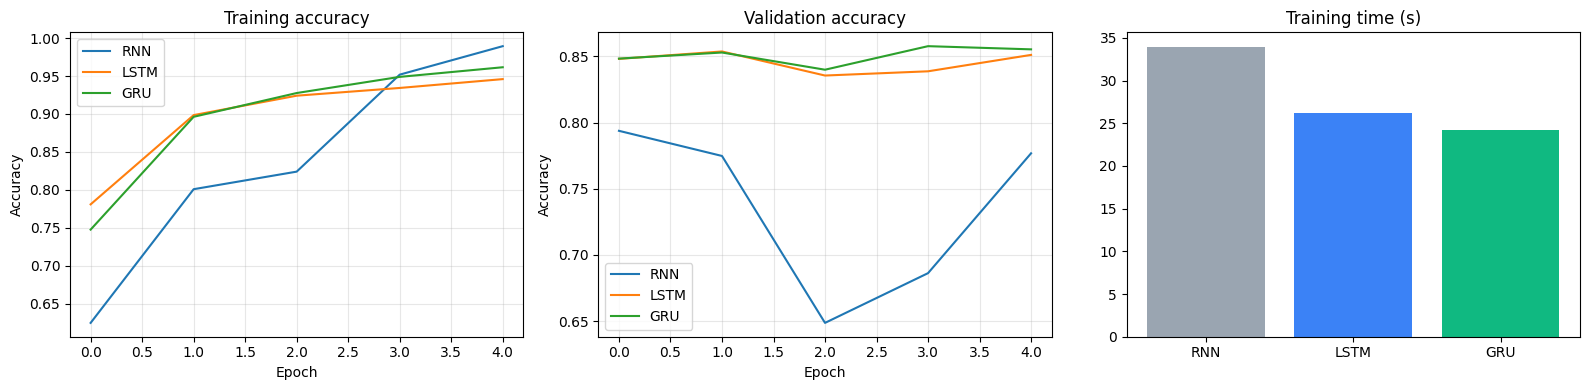

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for name, h in histories.items():
    ax[0].plot(h["accuracy"], label=name)
    ax[1].plot(h["val_accuracy"], label=name)
ax[0].set_title("Training accuracy");   ax[1].set_title("Validation accuracy")
for a in ax[:2]:
    a.set_xlabel("Epoch"); a.set_ylabel("Accuracy"); a.legend(); a.grid(alpha=.3)
ax[2].bar(df.index, df["Training Time (s)"], color=["#9aa5b1", "#3b82f6", "#10b981"])
ax[2].set_title("Training time (s)")
plt.tight_layout()
plt.savefig("comparison_plots.png", dpi=150)
plt.show()

## 8. Analysis
Fill this cell using **your** numbers from Section 6 and the plots in Section 7. Guiding questions:
1. Which model has the best F1-score, and is the gap large or within run-to-run noise?
2. Do Precision and Recall differ for any model, i.e. does it favour one class?
3. Which model was fastest, and does the extra cost of LSTM buy a real accuracy gain?
4. Do the training and validation curves show overfitting or unstable learning (especially for RNN)?
5. Which model would you choose for this task and why?

**Caveat:** results come from one seed. For a stronger claim, rerun with 3 seeds (change `SEED`) and report mean ± std.

In [10]:
best = df["F1-score"].idxmax()
print("Best by F1-score :", best)
print("Fastest          :", df["Training Time (s)"].idxmin())

Best by F1-score : GRU
Fastest          : GRU
